## Help ME I suck in this dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/T1.csv")

In [3]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645904,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50530 entries, 0 to 50529
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Date/Time                      50530 non-null  str    
 1   LV ActivePower (kW)            50530 non-null  float64
 2   Wind Speed (m/s)               50530 non-null  float64
 3   Theoretical_Power_Curve (KWh)  50530 non-null  float64
 4   Wind Direction (°)             50530 non-null  float64
dtypes: float64(4), str(1)
memory usage: 1.9 MB


In [5]:
df.isnull().sum()

Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
dtype: int64

In [6]:
# ANN OR LSTM Because there is time

In [7]:
# Target = Theoretical_Power_Curve

In [8]:
df.describe()

,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530.000000,50530.000000,50530.000000,50530.000000
mean,1307.684332,7.557952,1492.175463,123.687559
std,1312.459242,4.227166,1368.018238,93.443736
min,-2.471405,0.000000,0.000000,0.000000
25%,50.677890,4.201395,161.328167,49.315437
50%,825.838074,7.104594,1063.776282,73.712978
75%,2482.507568,10.300020,2964.972462,201.696720
max,3618.732910,25.206011,3600.000000,359.997589


In [9]:
df[df["Wind Speed (m/s)"] == 0]

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
1478,11 01 2018 09:50,0.0,0.0,0.0,0.0
3629,30 01 2018 16:40,0.0,0.0,0.0,0.0
14647,17 04 2018 06:50,0.0,0.0,0.0,0.0
17116,04 05 2018 13:10,0.0,0.0,0.0,0.0
20369,27 05 2018 03:50,0.0,0.0,0.0,0.0
23280,16 06 2018 15:40,0.0,0.0,0.0,0.0
24819,27 06 2018 14:00,0.0,0.0,0.0,0.0
36045,13 09 2018 19:50,0.0,0.0,0.0,0.0
46598,04 12 2018 14:50,0.0,0.0,0.0,0.0
46637,04 12 2018 21:30,0.0,0.0,0.0,0.0


In [10]:
df = df[df["Wind Speed (m/s)"] != 0]

In [11]:
df

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645904,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286
...,...,...,...,...,...
50525,31 12 2018 23:10,2963.980957,11.404030,3397.190793,80.502724
50526,31 12 2018 23:20,1684.353027,7.332648,1173.055771,84.062599
50527,31 12 2018 23:30,2201.106934,8.435358,1788.284755,84.742500
50528,31 12 2018 23:40,2515.694092,9.421366,2418.382503,84.297913


In [12]:
df.describe()

,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50520.000000,50520.000000,50520.000000,50520.000000
mean,1307.943177,7.559448,1492.470826,123.712041
std,1312.460160,4.226247,1367.992514,93.436777
min,-2.471405,0.205178,0.000000,0.000000
25%,51.139571,4.202664,161.575837,49.331057
50%,826.178192,7.105505,1064.198759,73.730484
75%,2482.687012,10.300642,2965.303613,201.699131
max,3618.732910,25.206011,3600.000000,359.997589


In [13]:
df[df["Theoretical_Power_Curve (KWh)"] == 0]

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
384,03 01 2018 16:00,-0.393068,2.185888,0.0,238.410294
385,03 01 2018 16:10,0.000000,2.142016,0.0,234.762405
386,03 01 2018 16:20,0.000000,2.501406,0.0,223.308807
387,03 01 2018 16:30,0.000000,2.668578,0.0,226.051697
491,04 01 2018 12:40,0.000000,2.888112,0.0,0.000000
...,...,...,...,...,...
50460,31 12 2018 12:20,0.000000,2.722504,0.0,82.736252
50461,31 12 2018 12:30,0.000000,2.869853,0.0,81.974297
50465,31 12 2018 13:10,0.000000,2.998981,0.0,76.018478
50466,31 12 2018 13:20,0.000000,2.647908,0.0,78.276291


In [14]:
df[df["Wind Direction (°)"]==0]

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
491,04 01 2018 12:40,0.0,2.888112,0.000000,0.0
509,04 01 2018 15:40,0.0,4.436895,208.760611,0.0
768,06 01 2018 11:30,0.0,3.577557,61.167602,0.0
804,06 01 2018 17:30,0.0,4.704412,266.565908,0.0
1476,11 01 2018 09:30,0.0,10.526490,3078.324921,0.0
...,...,...,...,...,...
46600,04 12 2018 15:20,0.0,6.411019,771.622088,0.0
46638,04 12 2018 21:40,0.0,6.443037,783.888657,0.0
46691,05 12 2018 06:30,0.0,11.770780,3481.717742,0.0
48436,17 12 2018 11:00,0.0,1.821791,0.000000,0.0


In [15]:
df[df["LV ActivePower (kW)"]==0
] 

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
382,03 01 2018 15:40,0.0,3.743307,83.986265,245.068207
385,03 01 2018 16:10,0.0,2.142016,0.000000,234.762405
386,03 01 2018 16:20,0.0,2.501406,0.000000,223.308807
387,03 01 2018 16:30,0.0,2.668578,0.000000,226.051697
388,03 01 2018 16:40,0.0,3.034003,17.180593,221.086502
...,...,...,...,...,...
50465,31 12 2018 13:10,0.0,2.998981,0.000000,76.018478
50466,31 12 2018 13:20,0.0,2.647908,0.000000,78.276291
50467,31 12 2018 13:30,0.0,2.796982,0.000000,68.145531
50468,31 12 2018 13:40,0.0,3.670288,73.392108,71.954659


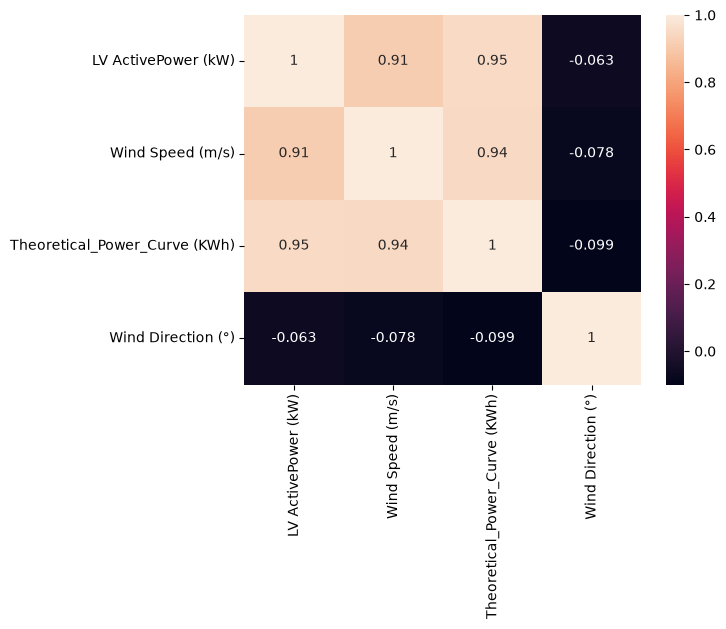

In [16]:
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X = df.drop("Theoretical_Power_Curve (KWh)",axis=1)

In [19]:
y = df["Theoretical_Power_Curve (KWh)"]

In [20]:
X_train,X_temp,y_train,y_temp = train_test_split(X,y,test_size=0.33,random_state=15)

In [21]:
X_val,X_test,y_val,y_test = train_test_split(X_temp,y_temp,test_size=0.5,random_state=15)

In [22]:
import tensorflow as tf

In [23]:
from tensorflow.keras.models import Sequential

In [47]:
model = Sequential()

In [26]:
from tensorflow.keras.layers import Dense

In [27]:
from tensorflow.keras.layers import Dropout,Input

In [44]:
for X_ in (X_train, X_test):
    dt = pd.to_datetime(X_["Date/Time"], format="%d %m %Y %H:%M")
    X_["Hour"] = dt.dt.hour
    X_["Month"] = dt.dt.month
    X_["DayOfYear"] = dt.dt.dayofyear
    X_.drop(columns="Date/Time", inplace=True)

In [29]:
X_train

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Wind Direction (°)
43321,2018-11-08 05:00:00,1158.939941,7.819954,73.733383
41022,2018-10-23 02:20:00,2022.387939,9.292296,69.226143
14315,2018-04-14 22:00:00,3490.080078,13.549280,83.281197
47317,2018-12-09 14:50:00,3602.222900,16.419451,185.156403
18759,2018-05-15 23:00:00,3089.167969,11.885160,200.557098
...,...,...,...,...
39304,2018-10-11 04:00:00,1746.249023,8.768386,60.297459
49025,2018-12-21 13:10:00,1537.687988,8.296704,209.921204
2694,2018-01-19 20:40:00,3601.173096,13.181830,194.391998
8078,2018-03-02 14:10:00,3097.660889,11.098980,207.568100


In [45]:
dt = pd.to_datetime(X_val["Date/Time"], format="%d %m %Y %H:%M")
X_val["Hour"] = dt.dt.hour
X_val["Month"] = dt.dt.month
X_val["DayOfYear"] = dt.dt.dayofyear
X_val.drop(columns="Date/Time", inplace=True)

In [48]:
model.add(Input(shape=(6,)))

In [49]:
model.add(Dense(64,activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(32,activation="relu"))

In [50]:
model.add(Dropout(0.2))

In [51]:
model.add(Dense(1))

In [52]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                      │ (None, 64)                  │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,561 (10.00 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
model.compile(optimizer='adam',loss="mse",metrics=["mae"])

In [39]:
from tensorflow.keras.callbacks import EarlyStopping

In [54]:
es = EarlyStopping(monitor='val_loss')

In [55]:
callbacks = []

In [56]:
callbacks.append(es)

In [59]:
history = model.fit(X_train,y_train,batch_size=128,epochs=100,validation_data=[X_val,y_val],callbacks=callbacks)

Epoch 1/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 455324.9062 - mae: 401.6646 - val_loss: 194010.0938 - val_mae: 201.7048
Epoch 2/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 302994.7812 - mae: 318.9904 - val_loss: 185354.7969 - val_mae: 195.9440
Epoch 3/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 286941.9688 - mae: 313.2254 - val_loss: 173240.3750 - val_mae: 186.1029
Epoch 4/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 270229.3125 - mae: 309.7489 - val_loss: 170953.5156 - val_mae: 212.7728
Epoch 5/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 246405.6094 - mae: 302.1298 - val_loss: 164944.9531 - val_mae: 235.4591
Epoch 6/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 227041.1094 - mae: 294.3045 - val_loss: 159142.9844 - val_mae: 239.8845
Epoch 7/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 203383.3281 - mae: 284.6335 - val_loss: 129685.2656 - val_mae: 216.4575
Epoch 8/100
265/265 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 187188

In [60]:
# Yoooo this is sucks

In [61]:
model2 = Sequential()

In [62]:
model2.add(Input(shape=(6,)))

In [64]:
model2.add(Dense(256,activation="relu"))
model2.add(Dropout(0.24))
model2.add(Dense(128,activation="relu"))
model2.add(Dropout(0.21))
model2.add(Dense(64))
model2.add(Dense(1)) # output

In [66]:
model2.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [67]:
model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                      │ (None, 256)                 │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 108,801 (425.00 KB)

 Trainable params: 108,801 (425.00 KB)

 Non-trainable params: 0 (0.00 B)

In [70]:
history = model2.fit(X_train,y_train,epochs=50,batch_size=128,validation_data=[X_val,y_val])

Epoch 1/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 85098.5938 - mae: 181.6078 - val_loss: 46549.8086 - val_mae: 125.3655
Epoch 2/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 77542.4062 - mae: 176.1087 - val_loss: 52293.1484 - val_mae: 138.1258
Epoch 3/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 77423.0391 - mae: 175.5363 - val_loss: 39695.9102 - val_mae: 130.1520
Epoch 4/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 70390.9297 - mae: 168.3619 - val_loss: 88385.9141 - val_mae: 203.0586
Epoch 5/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 71123.7656 - mae: 168.3554 - val_loss: 71810.1719 - val_mae: 181.2731
Epoch 6/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 64507.5820 - mae: 160.8878 - val_loss: 59964.8086 - val_mae: 163.7328
Epoch 7/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 60435.2070 - mae: 156.1199 - val_loss: 140964.6719 - val_mae: 261.9476
Epoch 8/50
265/265 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 60871.6367 - mae:

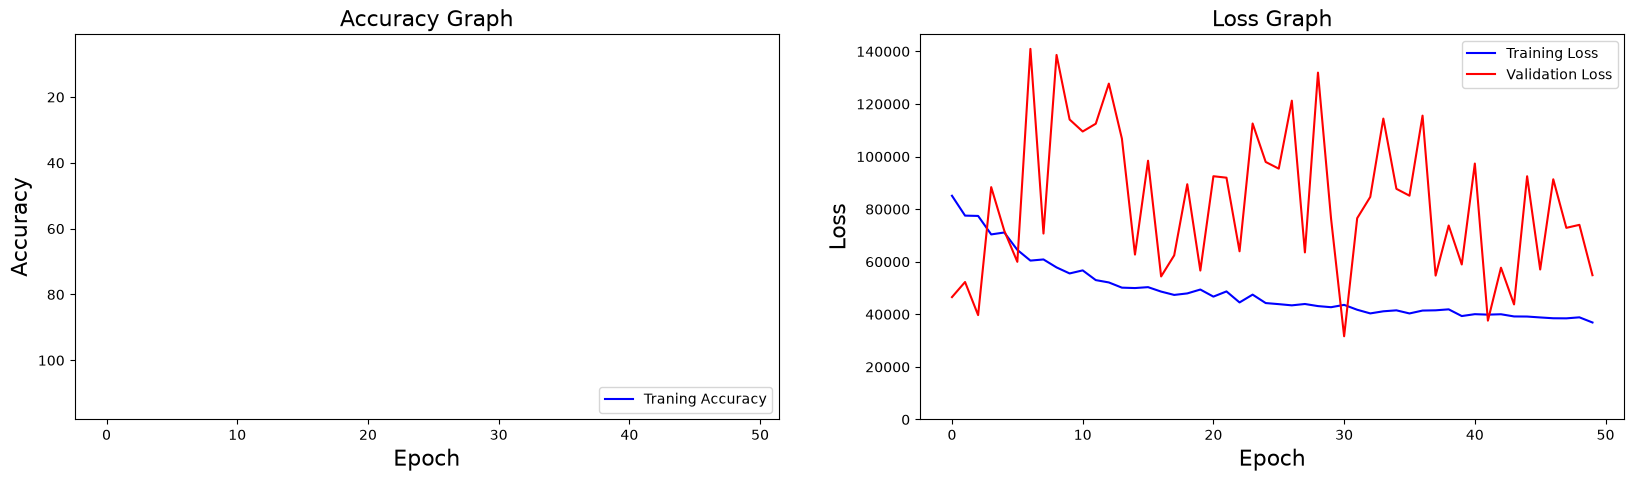

In [74]:
# ------------------------ Graphic 1 ACCURACY ----------------------------

plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(history.history['mae'],color='b',label="Traning Accuracy")
plt.legend(loc="lower right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Accuracy', fontsize=16)
plt.ylim([min(plt.ylim()),1])
plt.title("Accuracy Graph", fontsize=16)

# ------------------------ Graphic 2 LOSS --------------------------------

plt.subplot(1,2,2)
plt.plot(history.history['loss'], color='b', label='Training Loss')
plt.plot(history.history['val_loss'], color='r', label='Validation Loss')
plt.legend(loc="upper right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0,max(plt.ylim())])
plt.title("Loss Graph", fontsize=16)

plt.show()

In [76]:
model.evaluate(X_test,y_test, verbose=False)

[106206.6484375, 209.20449829101562]

In [77]:
model2.save("../model/wind_power_preditc.keras")